# Identification of Oral Taxa Absent from the HOMD Database — v2

**pipeline_v2 · GG2 2024.09 closed-reference scheme** — reproducible notebook ·
SEPP placement (2022.10 backbone) · edge x species-label phylotypes ·
vsearch closed-reference annotation (GG2 2024.09) · HOMD novelty re-check ·
STRICT candidates · 2026-08-18

> Design decisions (2026-08-18):
> 1. Phylotype = ASVs on the SAME SEPP edge; split only when members of one edge
>    annotate to different species/SGB at identity >= 97%.
> 2. Species annotation = vsearch `--usearch_global` vs GG2 2024.09 backbone
>    (`--iddef 2 --strand both`, qcov >= 0.9): >=99% -> species; 97-99% -> SGB;
>    <97% -> unannotated (deprioritized).
> 3. We do NOT claim taxa absent from GG2 itself; the claim is **HOMD misses real
>    oral microbes that are anchored in GG2**.
> 4. Result layers (support gate = subjects >50 & BioProjects >=2 & CONTINENTS >=2):
>    - SUPPORTED CATALOG: support gate + clean_phylotype;
>    - HEADLINE (the scientific claim): supported catalog + GG2 identity >=99%
>      + HOMD-uncaptured (species absent from HOMD catalog).

## Pipeline overview

| # | Stage | Script |
|---|-------|--------|
| 01 | Candidate generation & chimera removal | `01_chimera_removal.py` |
| 01b | Subject-level prevalence | `01b_subject_prevalence.py` |
| 02 | Contamination firewall (all control ASVs) | `02_contamination_firewall.py` |
| 04 | Support floor (>=2 BP, >=50 reads) + SEPP placement | `04_support_floor.py` + `04_sepp_place.sbatch` |
| 10 | GG2 2024.09 closed-reference annotation + edge x label phylotypes | `10_gg2_closedref_annot.py` |
| 11 | HOMD novelty re-check + STRICT candidates | `11_homd_novelty_strict.py` |
| 12 | Summary figures + strict-candidate tree | `12_make_summary_figs_v2.py` / `12b` / `12c` |


## Setup

In [1]:
import pandas as pd, numpy as np, json
from pathlib import Path
BASE = Path("/beegfs/huangxiaochang/global_oral/global-oral-microbiome/HOMD_uncapture_analysis")
PIPE_V2 = BASE / "pipeline_v2"
FIG = PIPE_V2 / "analysis_report" / "figs_v2"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
print("OK")

OK


## Step 01 — Candidate generation & chimera removal

Raw ASVs from 334 BioProjects (3,396,776) were collapsed by exact
sequence (100% identity) into 2,844,174 dereplicated sequences (`01_collect_asvs_and_abundance.py`).
Each derep sequence was mapped to HOMD V16.03 with vsearch (`--usearch_global`); the
candidate definition is **identity < 97% or no HOMD hit**. Chimeras were then removed
with vsearch `--uchime_ref` against a combined HOMD+GG2+SILVA reference. The retained
candidate set (`01_chimera_filtered.tsv`) has **1,136,142** HOMD-uncaptured, non-chimeric
sequences.

In [2]:
# heavy step (exact code that ran, outputs cached):
# vsearch --usearch_global derep.fa --db HOMD_16S_rRNA_RefSeq_V16.03_full.fasta \
#        --id 0.0 --iddef 2 --qcov-min 0 --userout exact_derep_vs_homd.hits.tsv
# vsearch --uchime_ref candidates.fa --db HOMD+GG2+SILVA.fa --nonchimeras ...

homd01 = pd.read_csv(PIPE_V2/"01_chimera_filtered.tsv", sep="\t", low_memory=False,
                     usecols=["derep_id","n_asvs","total_reads","identity",
                              "n_bioprojects","uncaptured_reason"])
print(f"HOMD-uncaptured & non-chimeric candidates: {len(homd01):,}")
print(homd01["uncaptured_reason"].value_counts(dropna=False).to_string())
print(f"total ASVs: {int(homd01['n_asvs'].sum()):,} | total reads: {homd01['total_reads'].sum():,.0f}")
print(homd01[["n_bioprojects","total_reads"]].describe().loc[["mean","50%","max"]].to_string())

HOMD-uncaptured & non-chimeric candidates: 1,136,142
uncaptured_reason
low_identity    1094651
no_hit            38766
low_qcov           2725
total ASVs: 1,283,959 | total reads: 598,978,997
      n_bioprojects   total_reads
mean       1.130104  5.272043e+02
50%        1.000000  1.600000e+01
max       36.000000  4.545400e+06


## Figure 1 — HOMD identity capture across thresholds

For ALL 2,844,174 derep sequences (captured + uncaptured), the fraction of
ASVs/reads captured at each HOMD identity threshold is computed (ASV-weighted and
read-weighted). Generated by `plot_figures.py` (fig1); the summary table below is
the saved output.

In [3]:
cap = pd.read_csv(FIG/"fig1_asv_weighted_identity_capture.tsv", sep="\t")
print(cap[["identity_label","asv_captured","asv_fraction","read_fraction"]].to_string(index=False))
print("\nAt the 97% candidate threshold:",
      f"{cap.loc[cap['identity_threshold']==97,'asv_fraction'].iloc[0]:.1%} of ASVs "
      f"({int(cap.loc[cap['identity_threshold']==97,'asv_captured'].iloc[0]):,}) are HOMD-captured")

identity_label  asv_captured  asv_fraction  read_fraction
          ≥80%     2854977.0      0.840496       0.980969
          ≥85%     2582850.0      0.760383       0.967735
          ≥90%     2028050.0      0.597051       0.945127
          ≥95%     1504790.0      0.443005       0.915229
          ≥97%     1353491.0      0.398463       0.902493
          ≥99%     1036006.0      0.304997       0.861770
        ≥99.5%      767877.0      0.226061       0.826123
          100%      325445.0      0.095810       0.720473

At the 97% candidate threshold: 39.8% of ASVs (1,353,491) are HOMD-captured


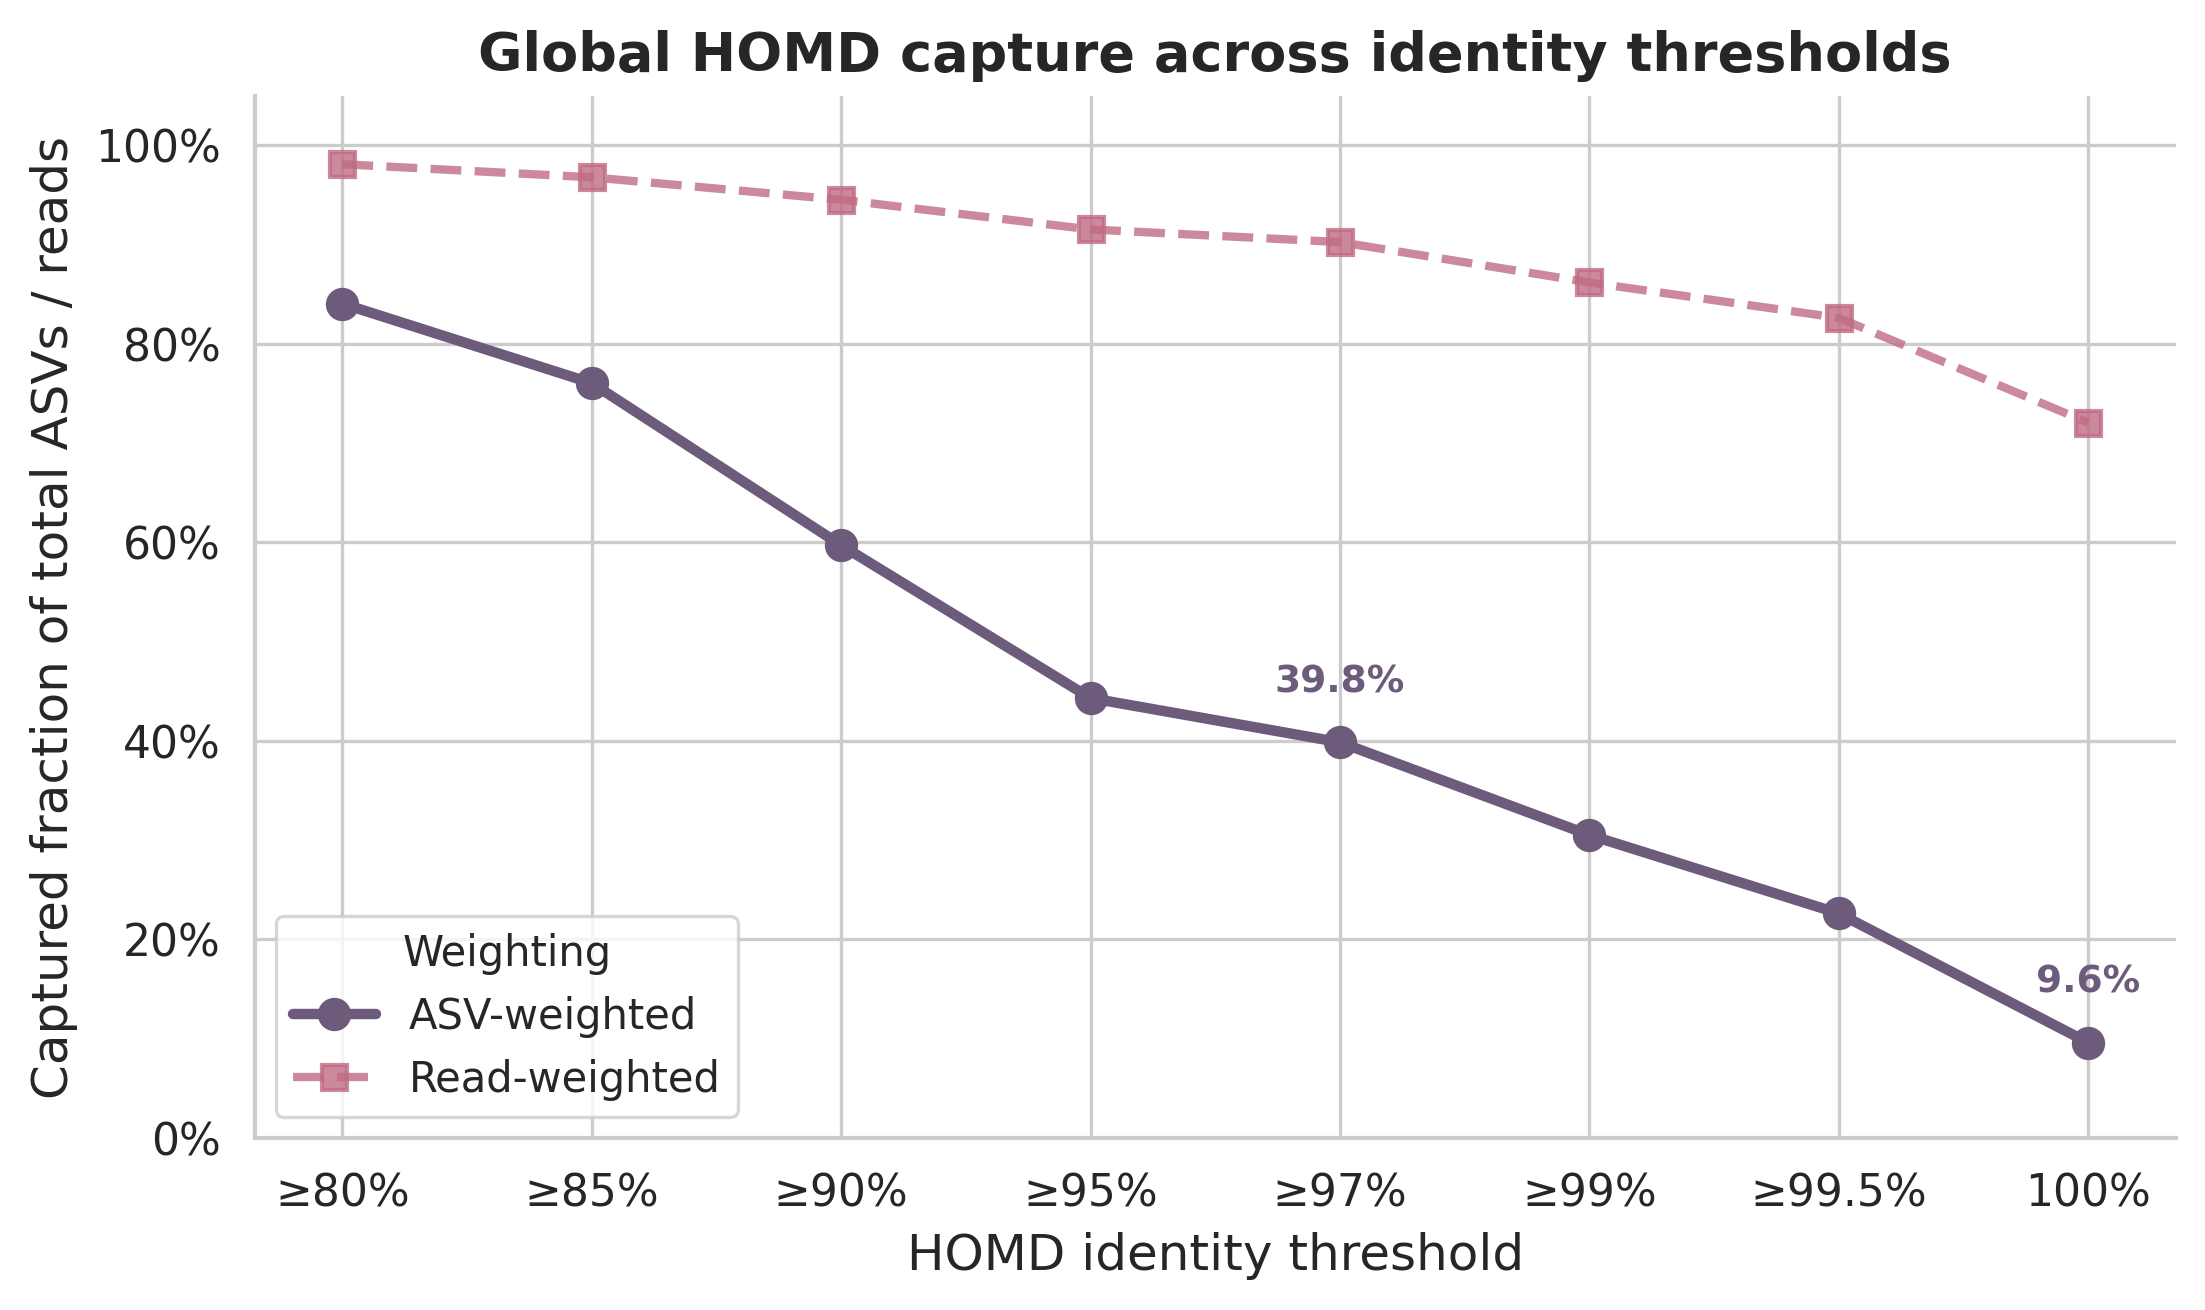

## Figure 2 — Subject prevalence by HOMD identity

Subject-level prevalence of derep sequences (distinct (bioproject, subject_id)
individuals), split by HOMD identity >=97% (captured) vs <97% (uncaptured). Generated by
`plot_figures.py` (fig2).

In [4]:
# heavy computation (plot_figures.py fig2): ECDF of subject_prevalence
# per identity group, weighted by n_asvs; KS test between the two groups.
# Saved figure below; exact code in plot_figures.py::fig2_prevalence_distribution.
print("fig2: ECDF of subject prevalence, >=97% vs <97% HOMD identity")

fig2: ECDF of subject prevalence, >=97% vs <97% HOMD identity


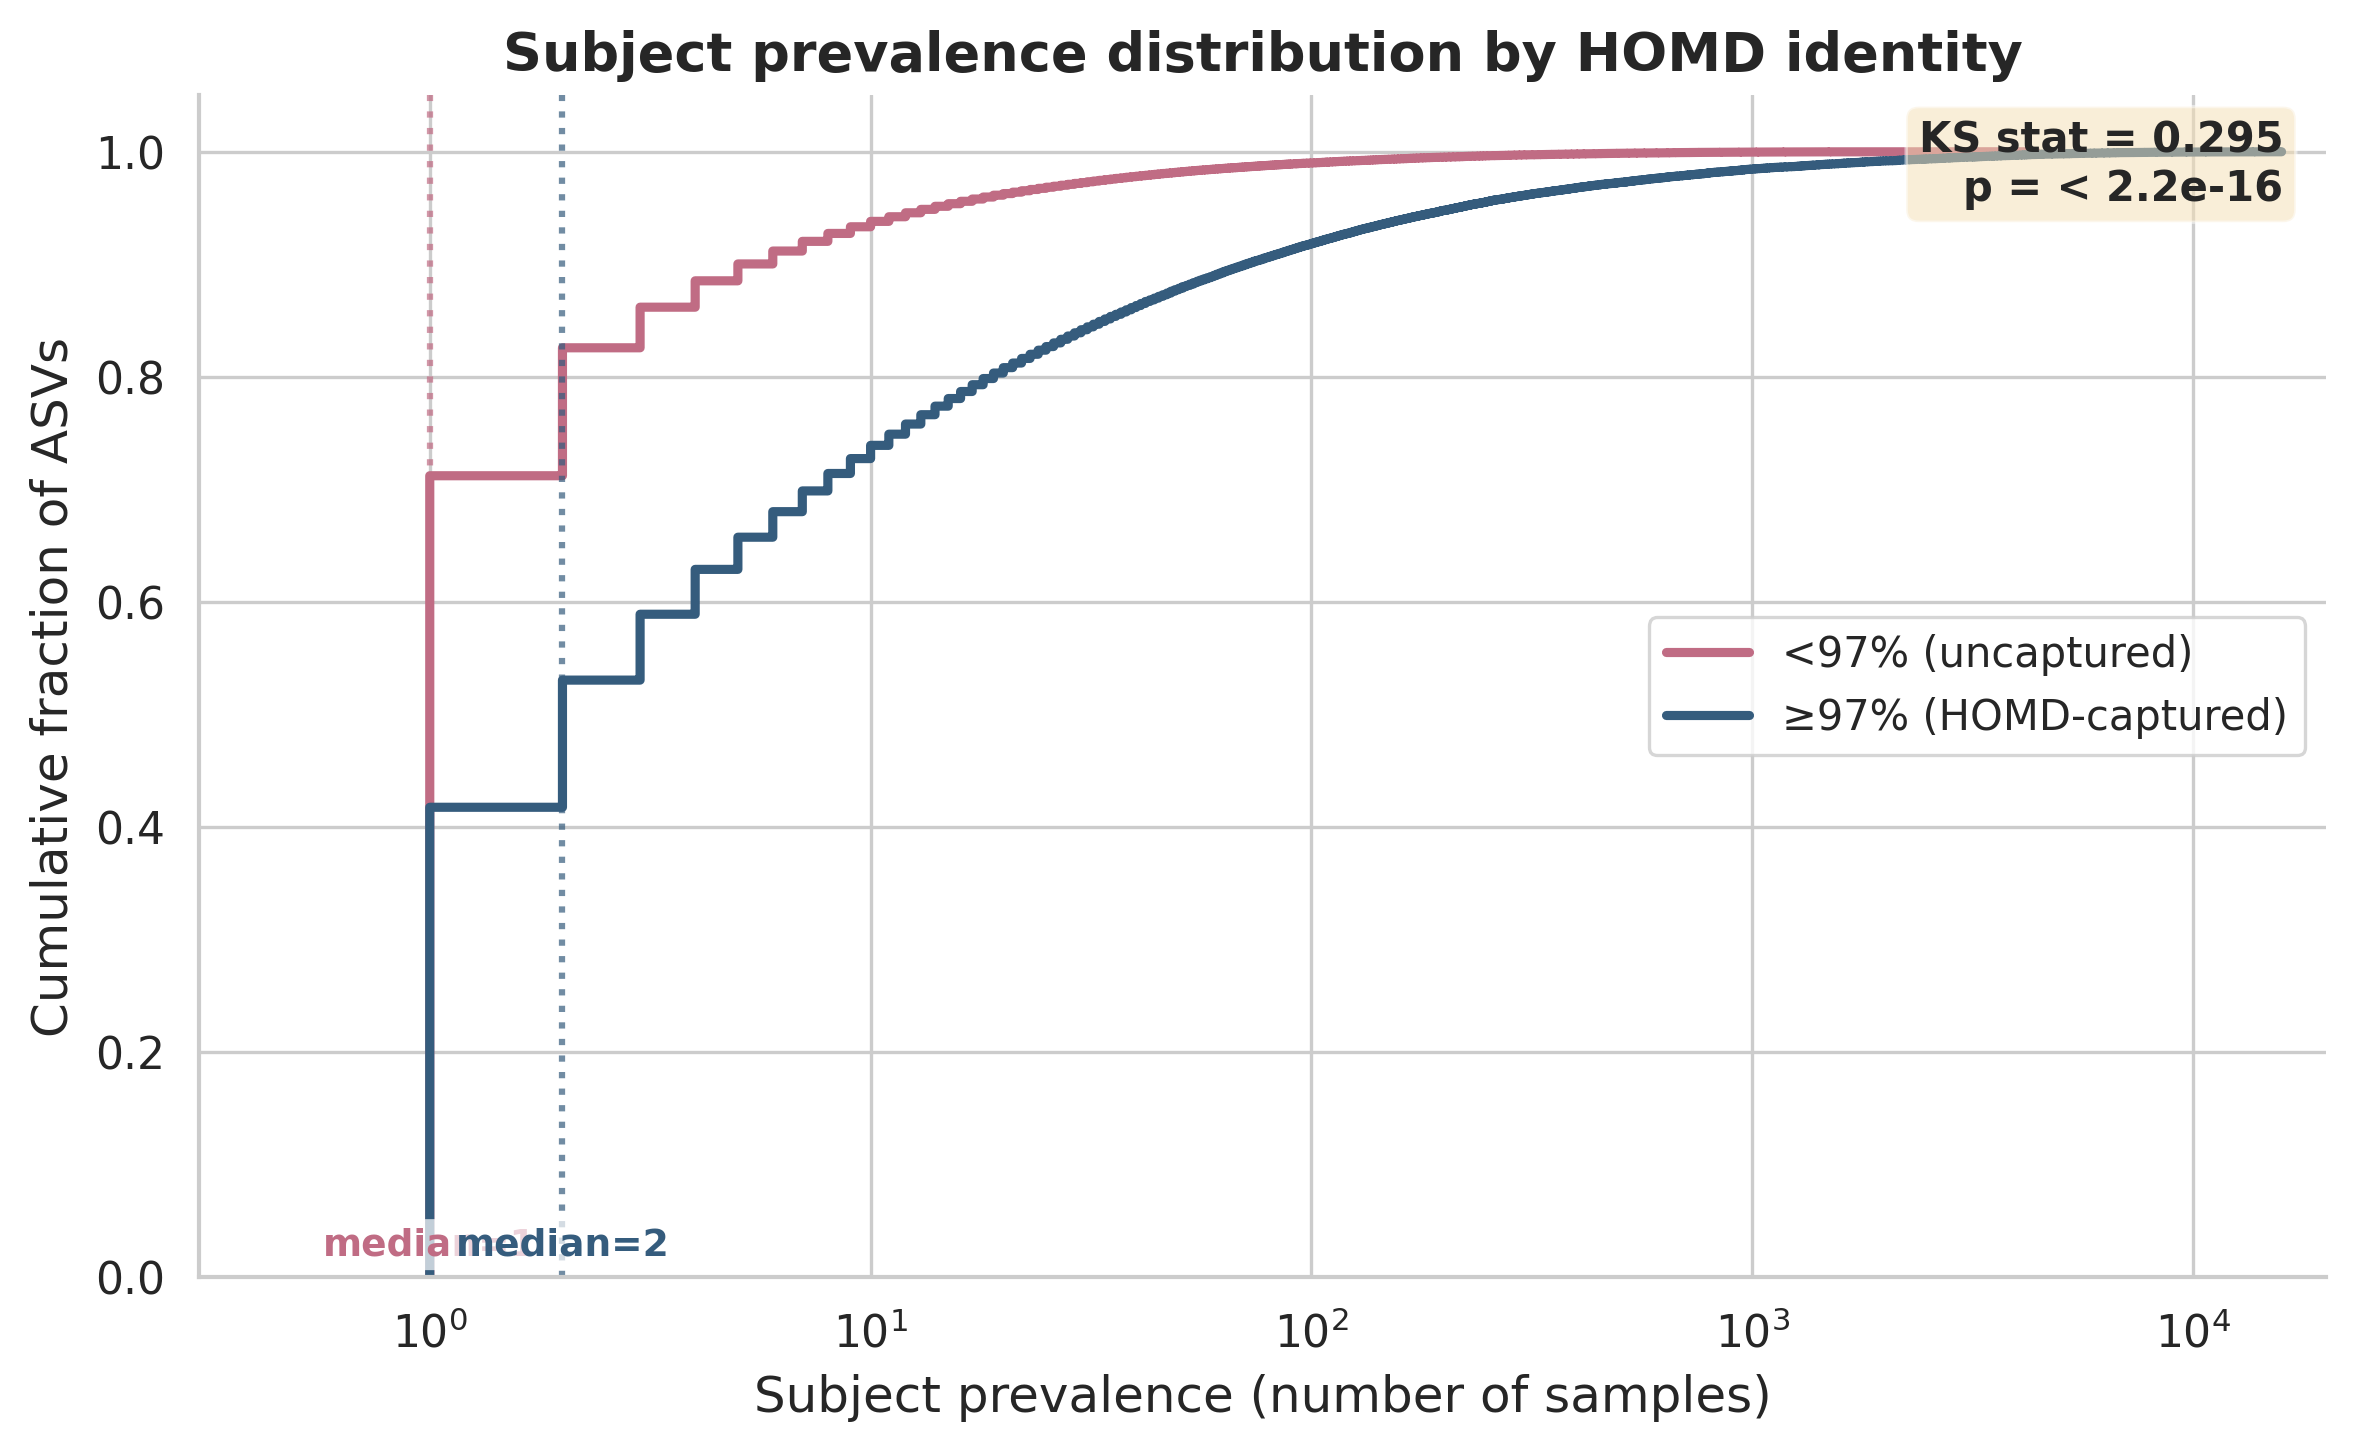

## Step 02 — Contamination firewall (flags only, nothing deleted)

Two annotation-only layers: (1) 97% vsearch clustering of ALL control-catalog
ASVs with the candidates — any cluster containing a control ASV flags all its candidate
members; (2) genus-level screen against an extended contaminant genus list (literature +
controls, excluding HOMD-present genera). Flags are columns, never deletions.

In [5]:
s02 = json.load(open(PIPE_V2/"02_summary.json"))
print("firewall:", s02["total_candidates"], "candidates ->",
      s02["clean"], "clean |", s02["any_flag"], "flagged")
print(s02["flag_type_distribution"])

firewall: 1136142 candidates -> 918172 clean | 217970 flagged
{'clean': 918172, 'cluster97': 156725, 'genus_list': 57295, 'both': 3950}


## Step 03 — Support floor (support only)

Flagged ASVs that reach the floor are **retained** with their annotations —
the floor filters on support (>=2 BioProjects, >=50 reads), never on contamination.

In [6]:
df = pd.read_csv(PIPE_V2/"02_contamination_flagged.tsv", sep="\t", low_memory=False)
df["n_bioprojects"] = pd.to_numeric(df["n_bioprojects"], errors="coerce").fillna(0)
df["total_reads"] = pd.to_numeric(df["total_reads"], errors="coerce").fillna(0)
passed = (df["n_bioprojects"]>=2) & (df["total_reads"]>=50)
print(f"support-floor passed: {int(passed.sum()):,} ASVs")
fl = df.loc[passed,"contamination_flag"].astype(str).str.lower().isin(["true","1","t"]).sum()
print(f"  clean: {int(passed.sum())-fl:,} | flagged (retained): {int(fl):,}")

support-floor passed: 54,290 ASVs
  clean: 32,628 | flagged (retained): 21,662


## Step 04 — SEPP placement on the GG2 backbone

Each surviving ASV is placed into the Greengenes2 2022.10 reference tree with
SEPP (best placement = argmax `like_weight_ratio`). Placements were reused from the
original pipeline run and re-run for the few missing ASVs.

In [7]:
# qiime fragment-insertion sepp \
#   --i-representative-sequences candidates.qza \
#   --i-reference-database 2022.10.backbone.sepp-reference.qza \
#   --p-threads 28 --o-tree tree.qza --o-placements placements.qza
# 05_phylotype_analysis.py: best_idx = argmax([p[2] for p in positions])
sp = pd.read_csv(PIPE_V2/"sepp_placements_reused.tsv", sep="\t", low_memory=False)
print(f"reused SEPP placements: {len(sp):,}")
print("median like_weight_ratio:", round(sp["like_weight_ratio"].median(), 4))

reused SEPP placements: 54,132
median like_weight_ratio: 0.3016


## Step 10 — GG2 2024.09 closed-reference annotation

Every support-floor ASV is searched with vsearch (`--usearch_global`,
`--iddef 2`, `--strand both`, `--maxaccepts 8`) against the GG2 2024.09 backbone
(337,506 full-length 16S; taxonomy 100% mapped). Tiers: >=99% species, 97-99% SGB,
<97% unannotated. Ambiguity = 2nd-best hit within 0.5% with a different species.

In [8]:
ann = pd.read_csv(PIPE_V2/"10_gg2_closedref_annotation.tsv", sep="\t", low_memory=False)
print(f"ASVs annotated: {len(ann):,}")
print(ann["tier"].value_counts().rename("tier").to_string())
print("\nambiguous by tier:")
print(ann.groupby("tier")["ambiguous"].mean().round(3).to_string())
print("\nmissing ASV (no valid hit):",
      len(set(pd.read_csv(PIPE_V2/"04_support_floor_passed.tsv", sep="\t",
          usecols=["derep_id"])["derep_id"]) - set(ann["derep_id"])))

ASVs annotated: 52,086
tier
species    30062
none       15733
sgb         6291

ambiguous by tier:
tier
none       0.123
sgb        0.156
species    0.147



missing ASV (no valid hit): 2204


## Step 10 — phylotype (edge x label)

Phylotype = ASVs on the same SEPP edge. If one edge contains members
annotated to DIFFERENT species/SGB at >=97%, they are split (`EDGE_x__label`);
unannotated members form separate `unresolved` units so support is never pooled
across species.

In [9]:
phy = pd.read_csv(PIPE_V2/"10_phylotypes_edge_label.tsv", sep="\t", low_memory=False)
print(f"phylotypes: {len(phy):,} | clean: {int(phy['clean_phylotype'].sum()):,} "
      f"| GG2-anchored: {int(phy['gg2_anchored'].sum()):,}")
print(phy["rep_tier"].value_counts(dropna=False).to_string())

phylotypes: 26,311 | clean: 16,722 | GG2-anchored: 18,940
rep_tier
species    15387
none        6286
sgb         3553
NaN         1085


## Step 14 — Supported phylotype catalog (before novelty_class)

An important result layer independent of the HOMD novelty decision:
every phylotype passing the support gate **subjects > 50 & BioProjects >= 2 &
continents >= 2** AND with **no contamination-flagged member** (clean). The
HEADLINE candidates are the GG2>=99% + HOMD-uncaptured subset.

In [10]:
sup = pd.read_csv(PIPE_V2/"14_supported_phylotypes.tsv", sep="\t", low_memory=False)
print(f"supported phylotypes: {len(sup):,}")
print(sup["gg2_tier"].value_counts().rename("GG2 tier").to_string())
print(sup["novelty_class"].value_counts().rename("HOMD novelty").to_string())
print(f"clean: {int(sup['clean_phylotype'].sum()):,} | oral clade: {int(sup['oral_clade'].sum()):,} "
      f"| among them headline: {int(sup['headline'].sum()):,}")
show = ["phylotype_id", "rep_species", "rep_genus", "rep_identity", "gg2_tier",
        "novelty_class", "max_subject_prevalence", "n_bioprojects_total",
        "n_regions", "clean_phylotype", "oral_clade", "headline"]
print(sup[show].head(20).to_string(index=False))

supported phylotypes: 258
gg2_tier
<97% (unresolved)    198
>=99% (species)       37
97-99% (SGB)          23
novelty_class
homd_uncaptured    216
homd_captured       42
clean: 258 | oral clade: 80 | among them headline: 33
                       phylotype_id                        rep_species          rep_genus  rep_identity          gg2_tier   novelty_class  max_subject_prevalence  n_bioprojects_total  n_regions  clean_phylotype  oral_clade  headline
            EDGE_489621__unresolved                                NaN             RUG705          93.8 <97% (unresolved) homd_uncaptured                    1531                   15          4             True       False     False
                        EDGE_112323                                NaN     Capnocytophaga         100.0   >=99% (species) homd_uncaptured                    1154                   15          9             True        True      True
                        EDGE_535874         Peptoanaerobacter stomatis  Pepto

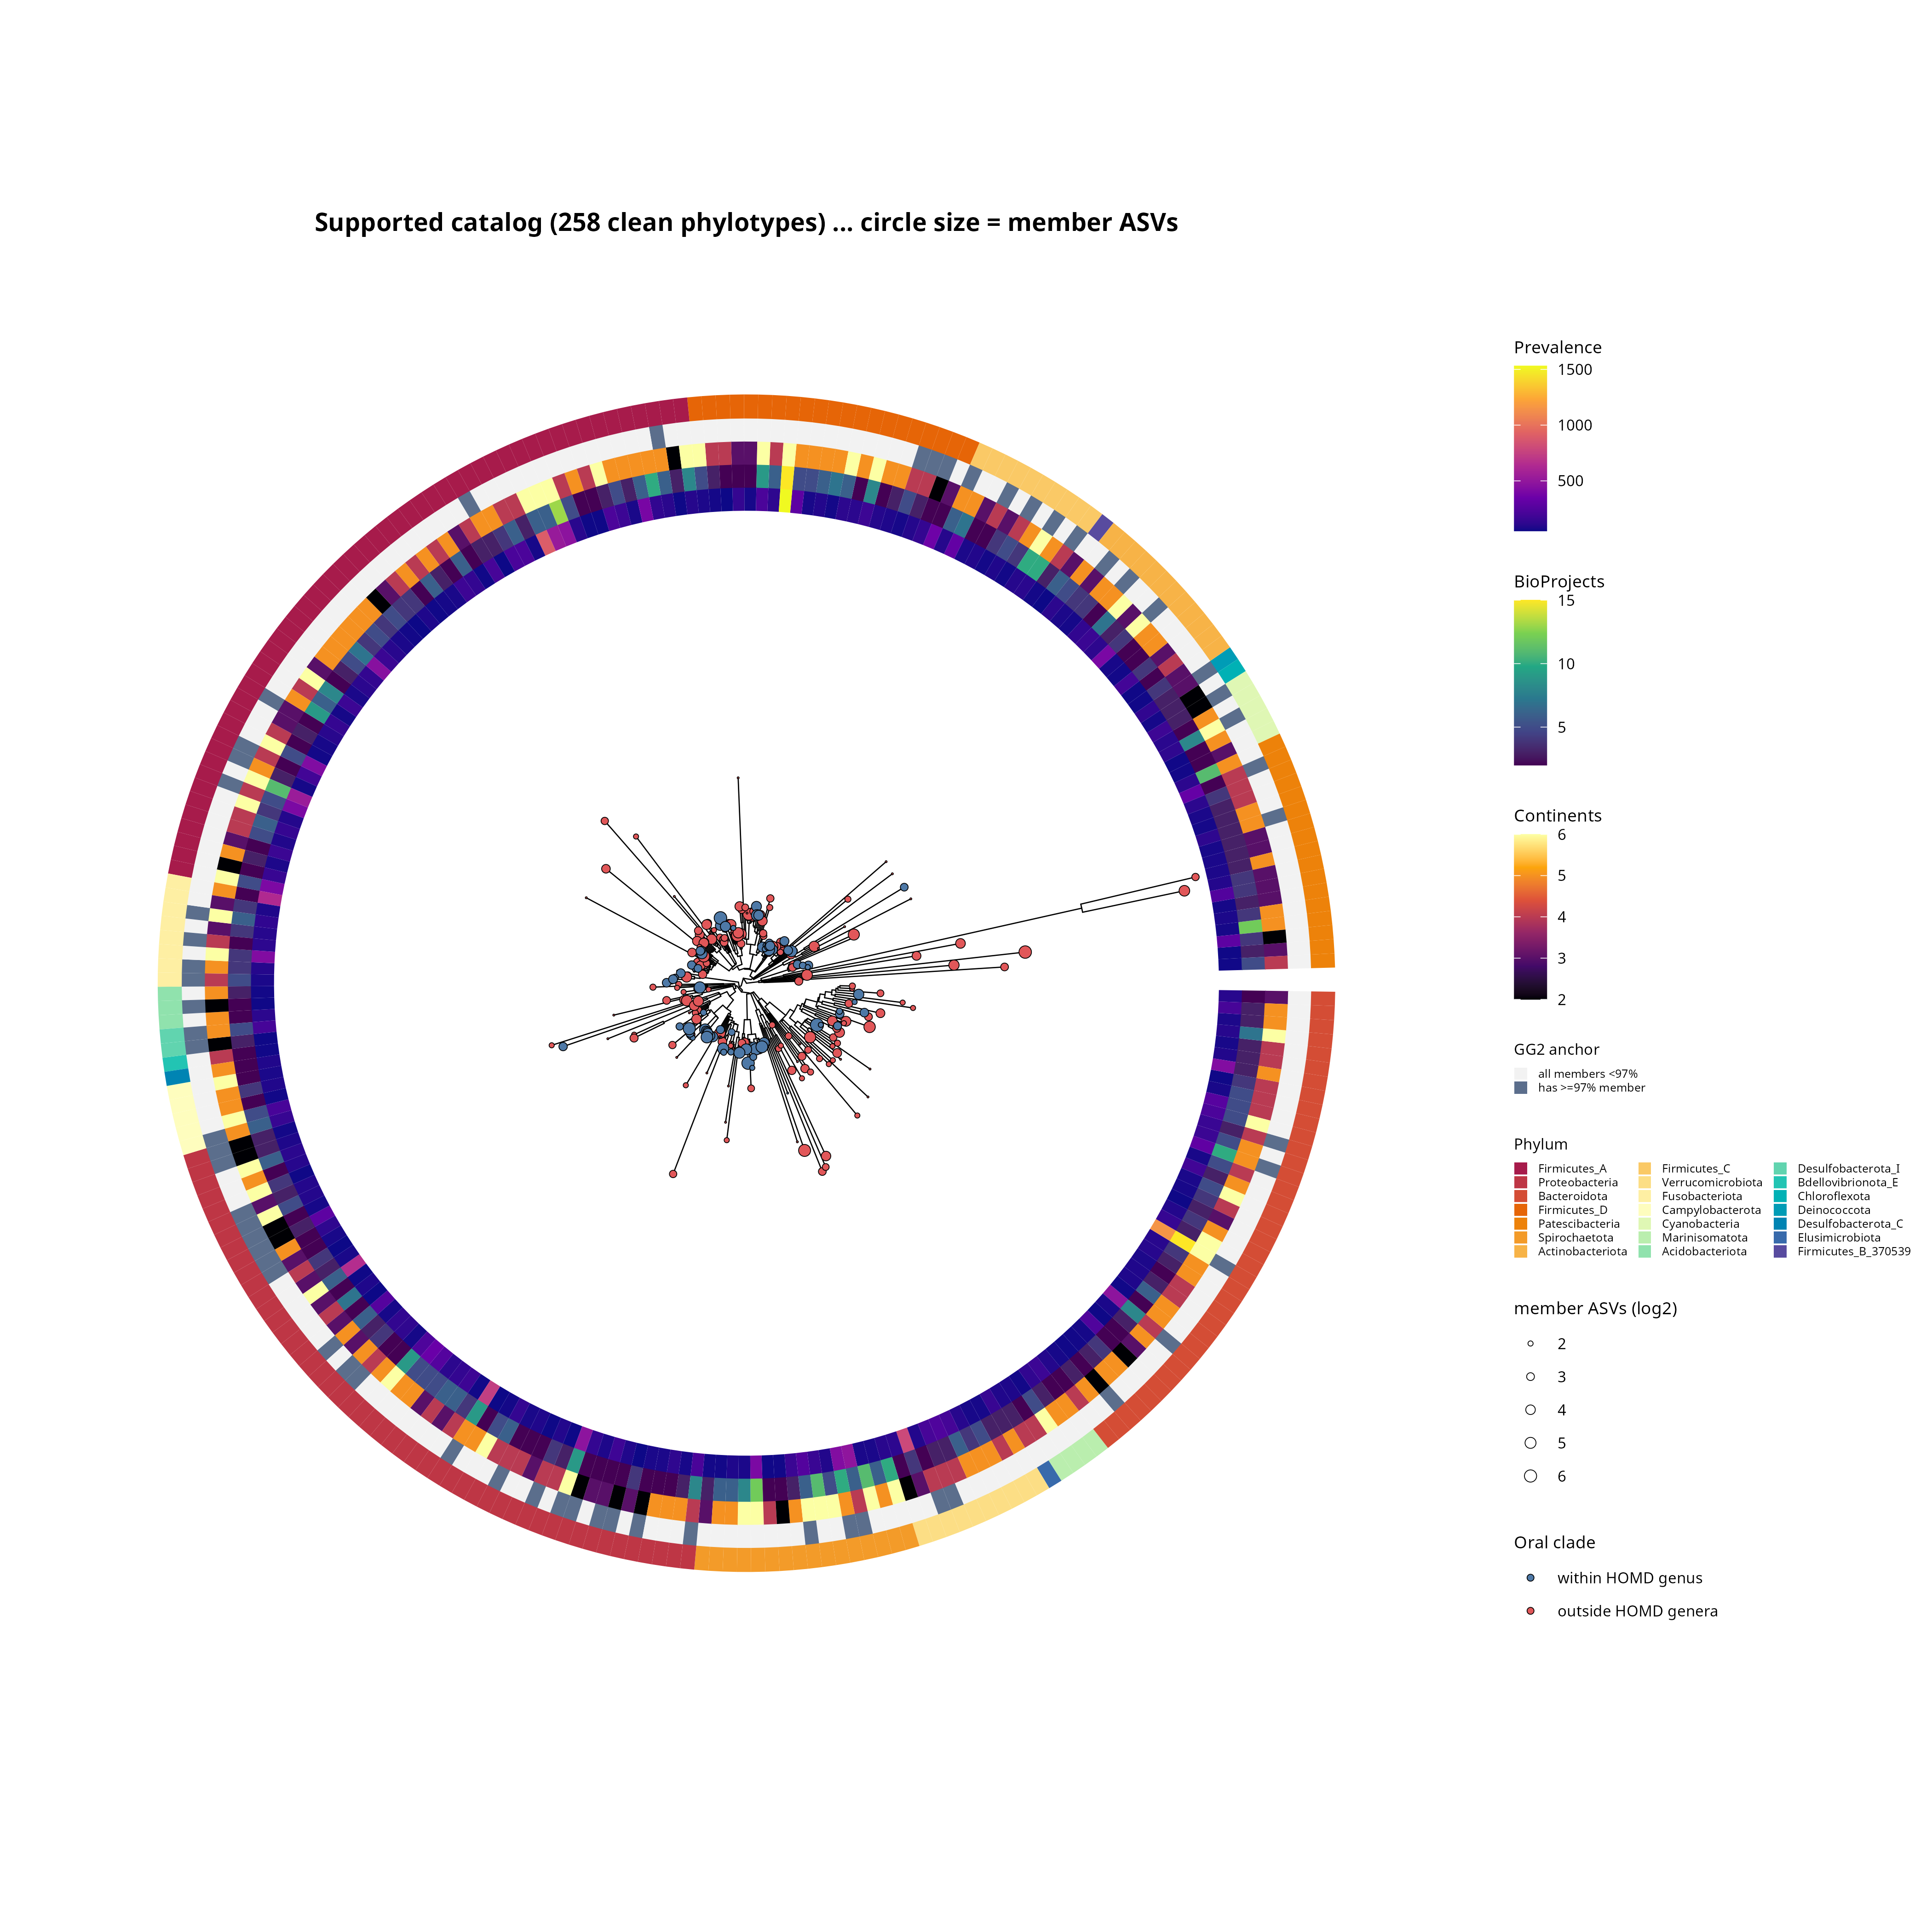

## Step 11 — HOMD novelty re-check + HEADLINE layer

For each new phylotype, the rep ASV's best HOMD identity (cached in step 01)
decides novelty: species name in HOMD catalog, >=97% HOMD hit, or a single-epithet
GTDB->HOMD synonym -> captured; otherwise uncaptured. SUPPORTED CATALOG =
support gate (subjects >50, BioProjects >=2, CONTINENTS >=2) AND clean_phylotype.
HEADLINE (the scientific claim) = supported catalog + GG2 identity >=99% +
homd_uncaptured.

In [11]:
nov = pd.read_csv(PIPE_V2/"11_phylotypes_homd_novelty.tsv", sep="\t", low_memory=False)
print(nov["novelty_class"].value_counts().to_string())
print(pd.crosstab(nov["novelty_class"], nov["oral_clade"].astype(str)).to_string())
supc = pd.read_csv(PIPE_V2/"11_supported_clean.tsv", sep="\t", low_memory=False)
hl = pd.read_csv(PIPE_V2/"11_headline_candidates.tsv", sep="\t", low_memory=False)
print(f"\nSUPPORTED CATALOG (clean): {len(supc):,} | HEADLINE candidates: {len(hl):,}")
show = ["phylotype_id", "n_asvs", "rep_species", "rep_genus", "rep_identity",
        "max_subject_prevalence", "n_bioprojects_total", "n_regions",
        "homd_best_id", "oral_clade"]
print(hl[show].head(15).to_string(index=False))

novelty_class
homd_uncaptured    24833
homd_captured       1478
oral_clade       False  True
novelty_class               
homd_captured      749   729
homd_uncaptured  22042  2791

SUPPORTED CATALOG (clean): 258 | HEADLINE candidates: 33
                                    phylotype_id  n_asvs                         rep_species             rep_genus  rep_identity  max_subject_prevalence  n_bioprojects_total  n_regions  homd_best_id  oral_clade
                                     EDGE_112323     112                                 NaN        Capnocytophaga         100.0                    1154                   15          9         89.53        True
                                      EDGE_95552      37                  Bergeyella cardium            Bergeyella         100.0                     480                    8          4         96.38       False
             EDGE_309337__Faucicola_mancuniensis      35              Faucicola mancuniensis             Moraxella         100.0 

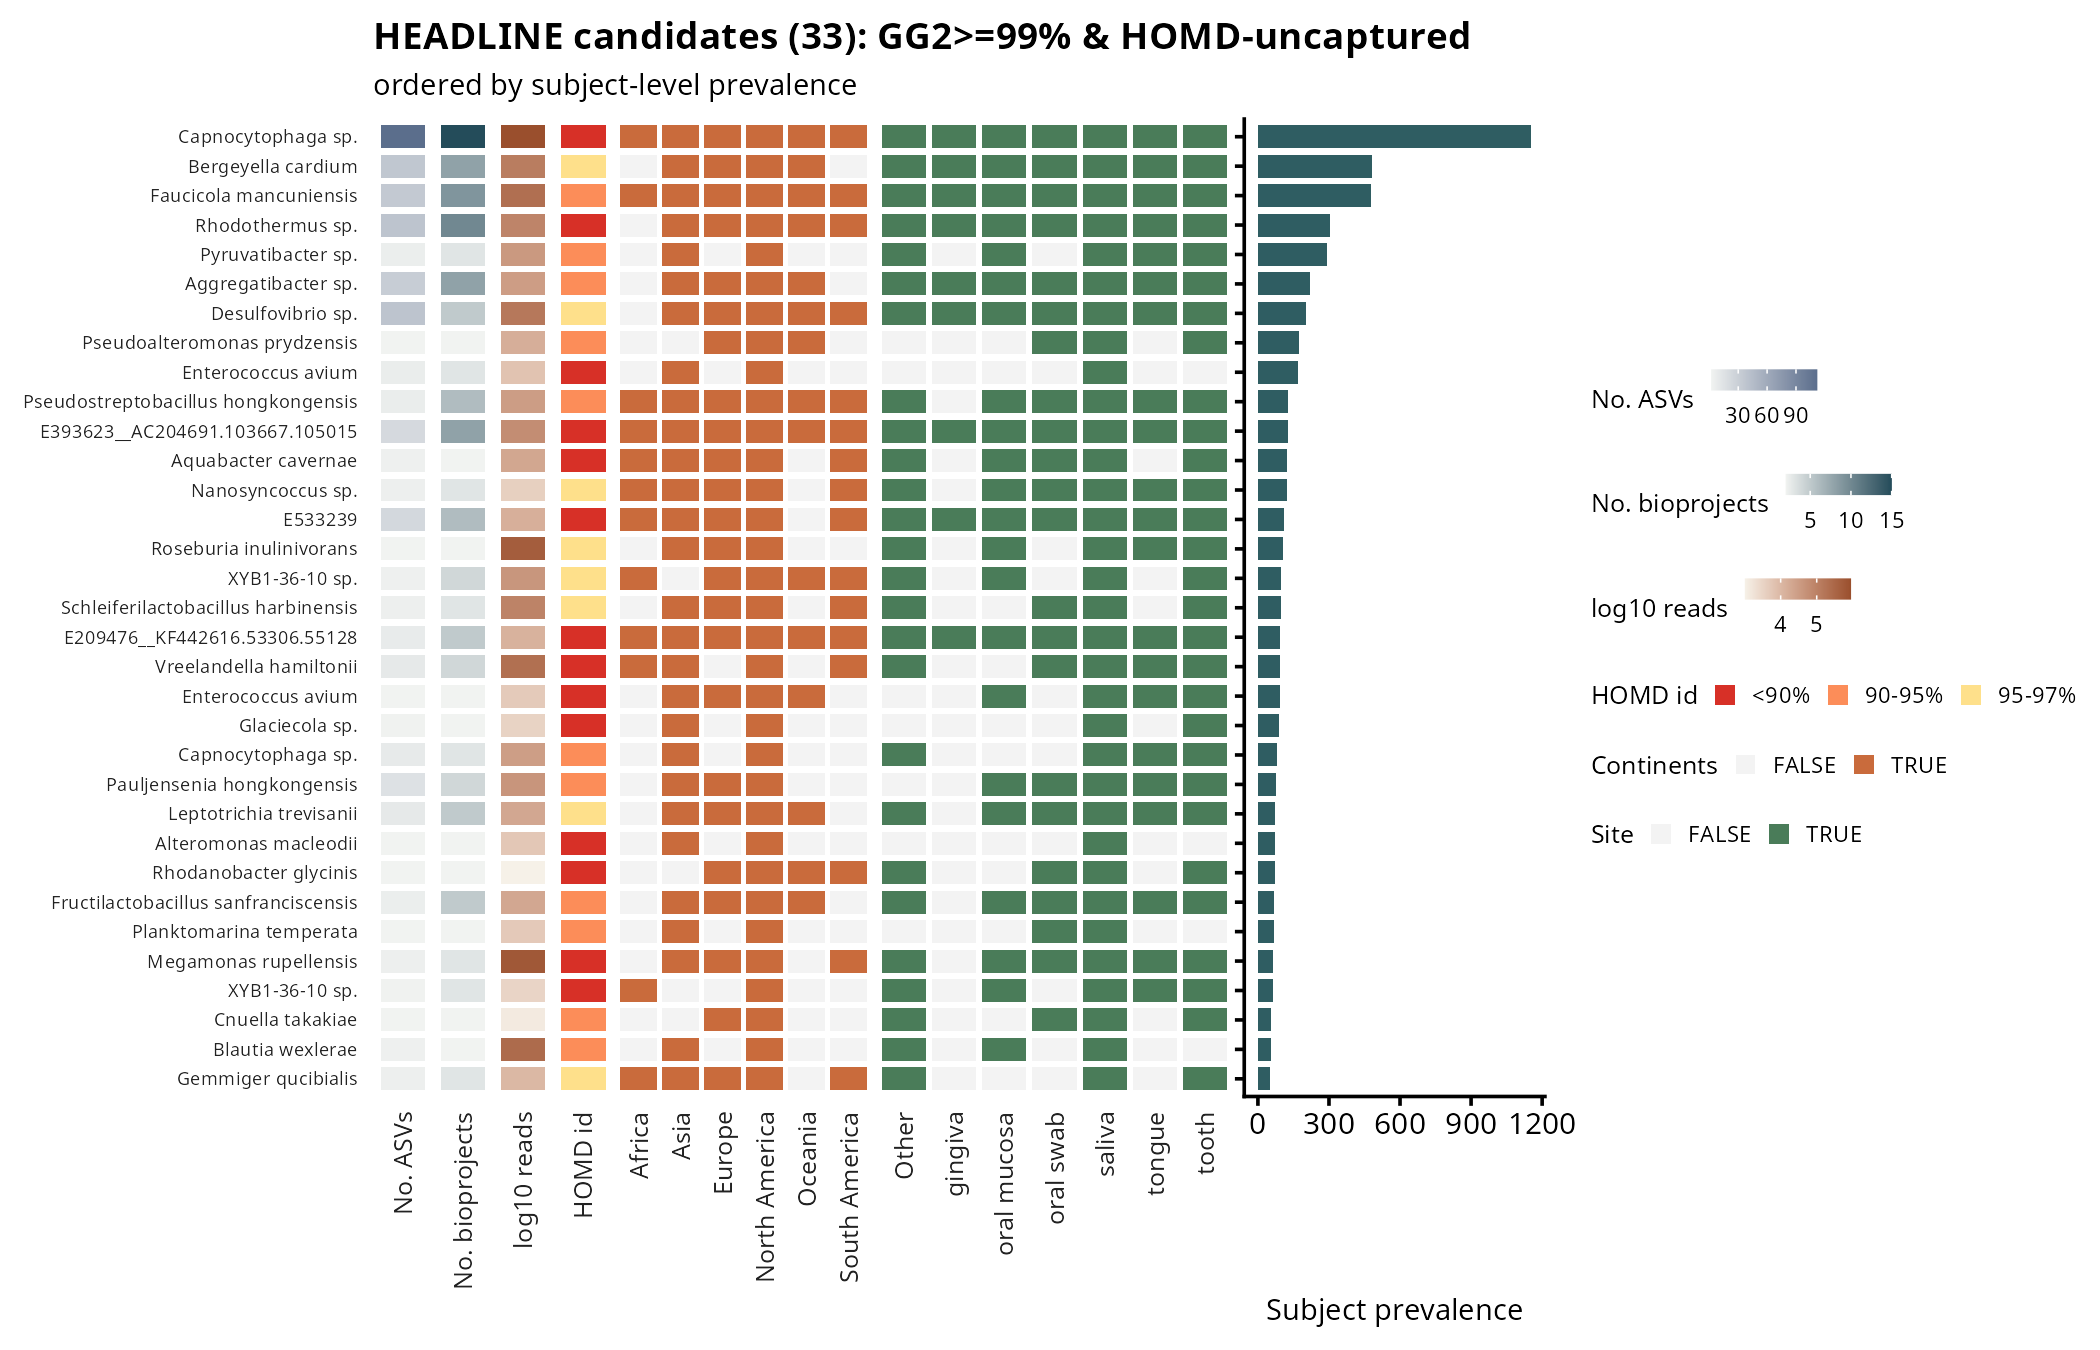

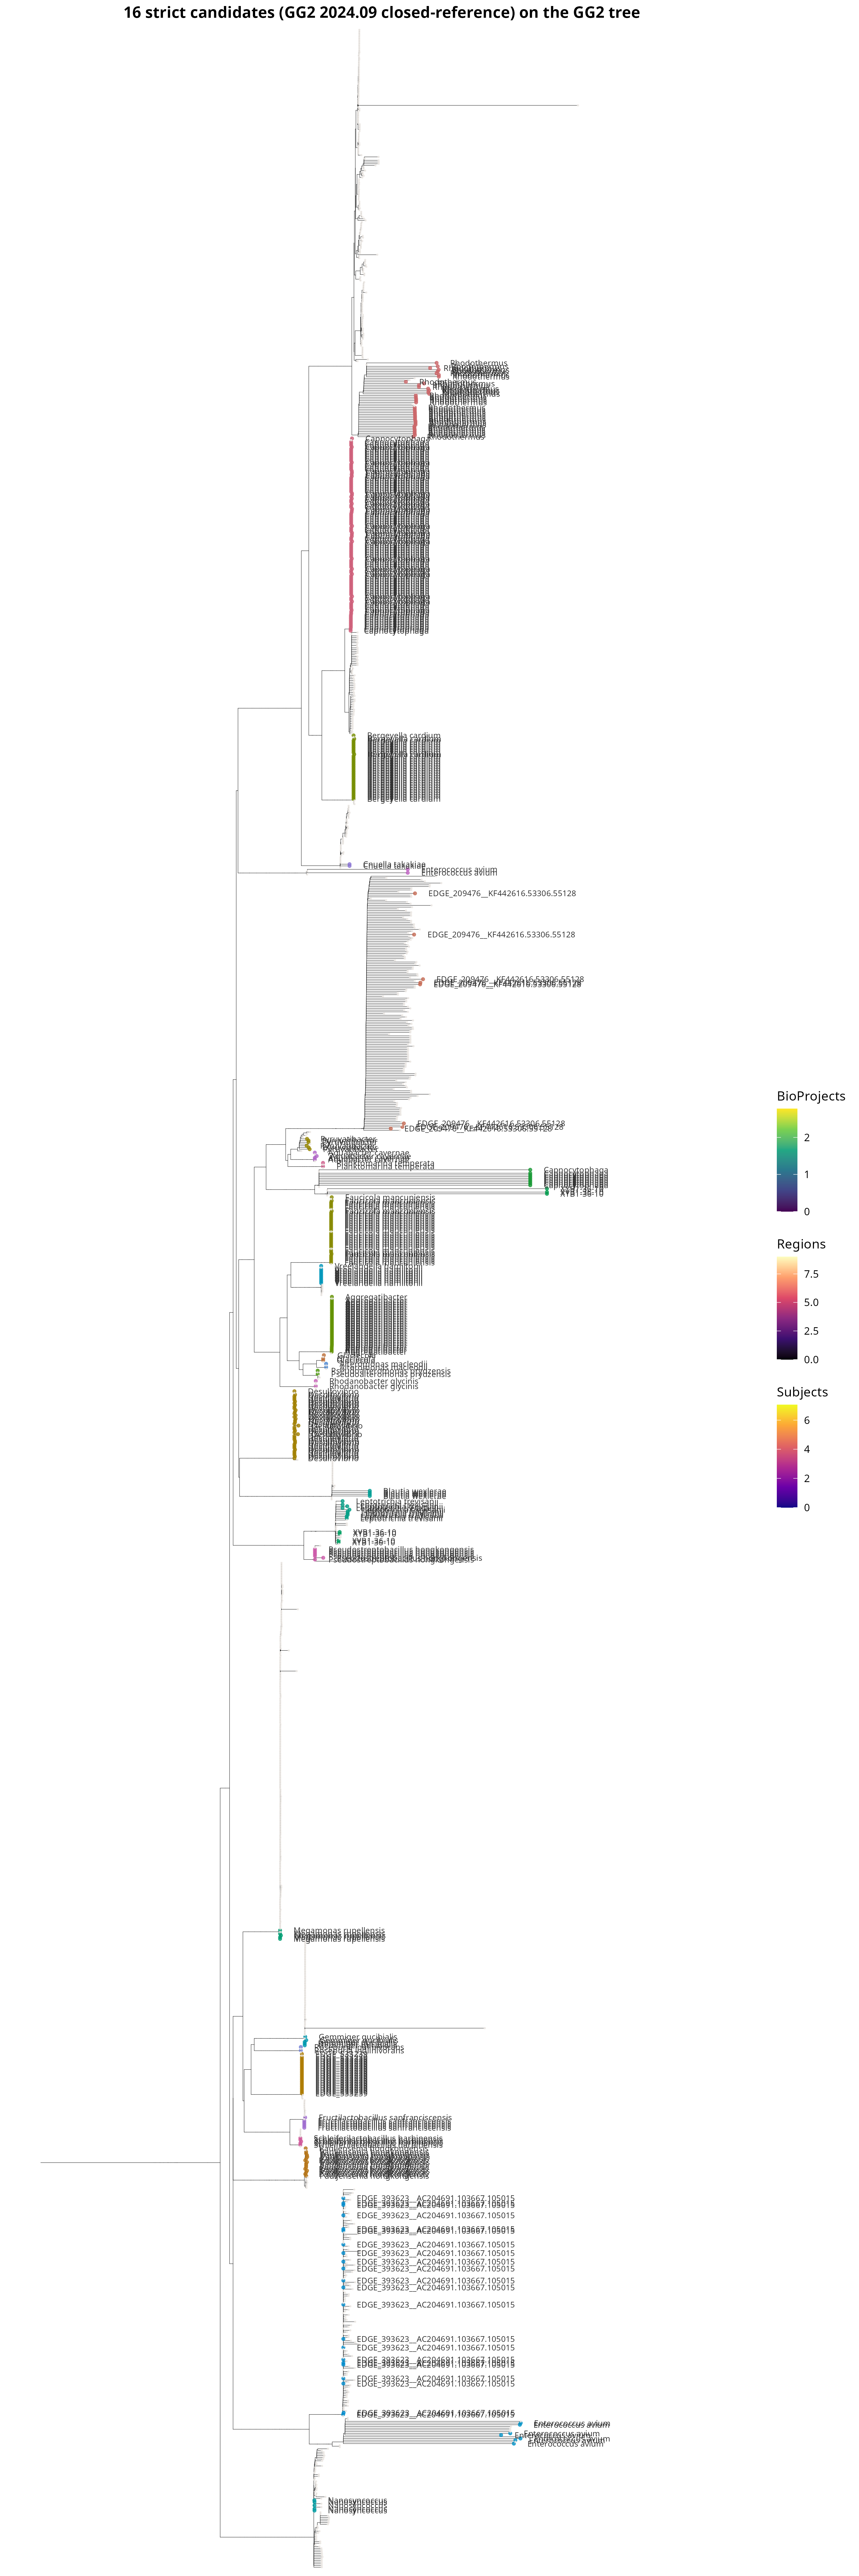

## Data funnel (summary)

In [12]:
d1  = len(pd.read_csv(PIPE_V2/"01_chimera_filtered.tsv", sep="\t", low_memory=False, usecols=["derep_id"]))
d4  = len(pd.read_csv(PIPE_V2/"04_support_floor_passed.tsv", sep="\t", low_memory=False, usecols=["derep_id"]))
s10 = json.load(open(PIPE_V2/"10_summary.json"))
s11 = json.load(open(PIPE_V2/"11_summary.json"))
funnel = pd.DataFrame({
    "Stage": ["ASVs screened (334 BioProjects)",
              "HOMD-uncaptured & non-chimeric",
              "Support floor (>=2 BP, >=50 reads)",
              "GG2 2024.09 annotated ASVs",
              "Phylotypes (edge x label)",
              "Supported catalog (clean)",
              "HEADLINE candidates"],
    "Count": [3396776, d1, d4, s10["n_asvs_annotated"], s10["n_phylotypes"],
              s11["n_supported_clean"], s11["headline"]],
})
print(funnel.to_string(index=False))

                             Stage   Count
   ASVs screened (334 BioProjects) 3396776
    HOMD-uncaptured & non-chimeric 1136142
Support floor (>=2 BP, >=50 reads)   54290
        GG2 2024.09 annotated ASVs   52086
         Phylotypes (edge x label)   26311
         Supported catalog (clean)     258
               HEADLINE candidates      33


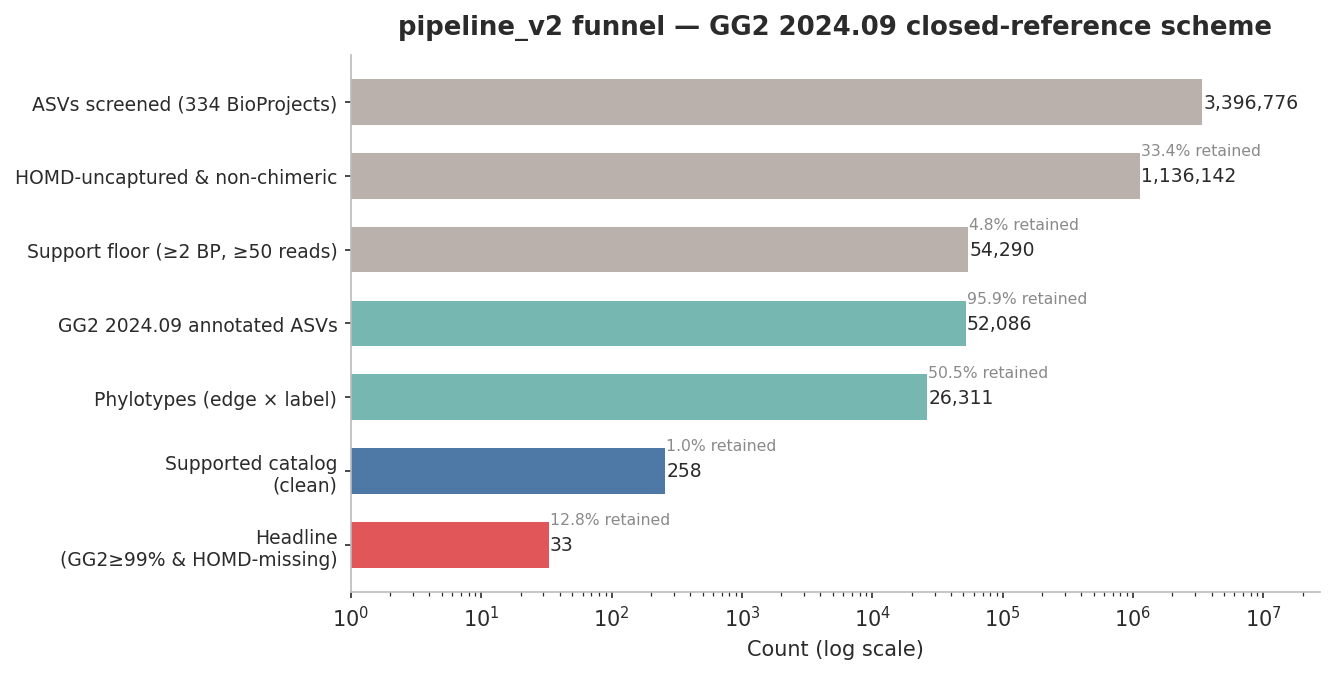

## Limitations

1. **Phylotype edges are from the 2022.10 SEPP placement**, while annotation
   uses GG2 2024.09; sequence-based labels are version-independent, edge structure
   is not (re-placement on 2024.09 is optional future work).
2. **GG2 2024.09 taxonomy has ~41% of tips with an empty species field** (31% of
   named species are `spNNN` placeholders); many >=99% hits therefore have no
   formal species name and are labelled at genus/SGB level.
3. **99%/97% identity is computed on short amplicon fragments** (median 273 bp);
   species calls from a single region are provisional.
4. **Ambiguous hits** (2nd best within 0.5% with a different species) are flagged,
   not resolved by fiat.
5. No oral-vs-environment adjudication: some strict candidates have very low HOMD
   identity and could be environmental/transient; retained by user decision.

---
*Report v2 built 2026-08-18.*